<a href="https://colab.research.google.com/github/Farida2025/2-adp2/blob/main/almaty_pm25_colab_en.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Almaty PM2.5 Retrospective Pilot

Run all cells, then select the six original data files when the upload prompt opens. The feasibility, pilot and paper figures are generated in one session. Download the figure ZIP from the Colab Files pane.


## Data Feasibility Study

Upload the six source files when prompted. The notebook accepts the original numbered filenames. The SHA-256 manifest identifies the local data snapshot.


In [1]:
from pathlib import Path
import os, json, hashlib, shutil, platform
from collections import Counter
from itertools import combinations
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
try:
    from IPython.display import display, Markdown
except ImportError:
    def display(*items):
        for item in items:
            _shown.append(item)
    Markdown = str
    _shown=[]

MODE='upload'
SAVE_TO_DRIVE=False
DOWNLOAD_ZIP=False
DATA=Path(os.getenv('ALMATY_INPUTS','/content/almaty_inputs'))
OUT=Path(os.getenv('ALMATY_OUTPUTS','/content/almaty_outputs'))
if MODE=='drive' or SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
if MODE=='drive': DATA=Path('/content/drive/MyDrive/almaty_inputs')
if SAVE_TO_DRIVE: OUT=Path('/content/drive/MyDrive/almaty_outputs')
if MODE=='upload' and not os.getenv('ALMATY_INPUTS'):
    from google.colab import files
    DATA.mkdir(parents=True,exist_ok=True)
    for name,data in files.upload().items(): (DATA/Path(name).name).write_bytes(data)
aliases=[
 ('pm25 (2).csv.gz','pm25.csv.gz','pm25 (2).csv'),
 ('stations (1).csv','stations.csv'),('station_periods (1).csv','station_periods.csv'),
 ('stations.geojson',),('DATA_DICTIONARY.md',),('DATASHEET (1).md','DATASHEET.md')]
def locate(names):
    for n in names:
        if (DATA/n).is_file(): return DATA/n
    raise FileNotFoundError(f'{DATA}: one of these files is required {names}')
paths=list(map(locate,aliases))
OUT.mkdir(parents=True,exist_ok=True)
CUT=pd.Timestamp('2024-01-01')
TZ=ZoneInfo('Asia/Almaty')
HOURS=(12,18,20); SIZES=(8,10,12)
LAT,LON=43.26,76.92
NEAR=200
MIN_DAYS,MIN_SEASON,MIN_CLASS=90,10,20
def save(df,name,index=False):
    df.to_csv(OUT/(name+'.csv'),index=index,encoding='utf-8-sig')
def md(df):
    f=df.astype(object).where(df.notna(),'—').astype(str)
    return '\n'.join(['| '+' | '.join(f.columns)+' |','| '+' | '.join(['---']*len(f.columns))+' |']+
        ['| '+' | '.join(v.replace('|','\\|').replace('\n',' ') for v in row)+' |' for row in f.itertuples(index=False,name=None)])
manifest=dict(inputs={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in paths},commit_sha=None,
 python=platform.python_version(),pandas=pd.__version__,numpy=np.__version__,timezone=str(TZ),test_start=str(CUT.date()),
 hours=HOURS,sizes=SIZES,zones=[LAT,LON],near_m=NEAR,screen=[MIN_DAYS,MIN_SEASON,MIN_CLASS])
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')


Saving DATASHEET (1).md to DATASHEET (1).md
Saving DATA_DICTIONARY.md to DATA_DICTIONARY.md
Saving stations.geojson to stations.geojson
Saving station_periods (1).csv to station_periods (1).csv
Saving stations (1).csv to stations (1).csv
Saving pm25 (2).csv.gz to pm25 (2).csv.gz


904

### 1. Input audit and station metadata

The Almaty export includes suburban locations. The initial audit covers the export. Candidate selection uses KazHydroMet posts labelled Almaty with consistent coordinates across observations, the registry and GeoJSON. Station history records flag documented location changes.


In [2]:
x=pd.read_csv(paths[0],dtype={c:'string' for c in ['station_id','datetime_utc','source','station_name','city','pollutant','parameter']})
assert {'station_id','datetime_utc','value_ugm3','lat','lon','source'}<=set(x), 'An hourly CSV is required'
raw_n=len(x)
schema=pd.DataFrame({'column':x.columns,'dtype':x.dtypes.astype(str).values,'missing':x.isna().sum().values})
save(schema,'input_schema'); display(schema)
if 'city' in x: x=x[x.city.str.strip().str.casefold().isin(['almaty','\u0430\u043b\u043c\u0430\u0442\u044b'])].copy()
for c in ['pollutant','parameter']:
    if c in x: x=x[x[c].str.casefold().str.replace(r'[^a-z0-9]','',regex=True).eq('pm25')].copy()
ids=sorted(x.station_id.dropna().unique())
reg=pd.read_csv(paths[1],dtype={'station_id':'string'}).set_index('station_id')
assert reg.index.is_unique
periods=pd.read_csv(paths[2],dtype={'station_id':'string'})
periods=periods[periods.station_id.isin(ids)]
save(periods,'matched_station_periods')
geo=json.loads(paths[3].read_text(encoding='utf-8-sig'))
g=[]
for f in geo['features']:
    st=f.get('properties',{}).get('station_id')
    p=f.get('geometry') or {}
    if st in ids and p.get('type')=='Point':
        lon,lat=p['coordinates'][:2]; g.append((st,lat,lon))
geo_points=pd.DataFrame(g,columns=['station_id','geo_lat','geo_lon']).drop_duplicates()
geo_conflict=geo_points.station_id.duplicated(keep=False)
g=geo_points[~geo_conflict].set_index('station_id')
docs=[]
for p,terms in zip(paths[4:],[('k-means','valid_to'),('kgmt_auto','reverse conversion','cluster outlier')]):
    for term in terms:
        docs.extend((p.name,term,i+1,line) for i,line in enumerate(p.read_text(encoding='utf-8-sig').splitlines()) if term in line.lower())
save(pd.DataFrame(docs,columns=['document','term','line_number','text']),'documentation_evidence')
pos=x[['station_id','lat','lon']].copy()
for c in ['lat','lon']: pos[c]=pd.to_numeric(pos[c],errors='coerce')
valid_pos=pos.lat.between(-90,90)&pos.lon.between(-180,180)
pos=pos[valid_pos].dropna().drop_duplicates()
save(pos,'observed_coordinates')
nloc=pos.groupby('station_id').size()
stable=pos[pos.station_id.map(nloc).eq(1)].set_index('station_id')
meta=pd.DataFrame(index=pd.Index(ids,name='station_id')).join(stable).join(reg.add_prefix('reg_')).join(g)
meta['location_count']=nloc.reindex(ids).fillna(0).astype(int)
meta['historical_period']=meta.index.isin(periods.station_id)
meta['sources']=x.groupby('station_id').source.agg(lambda a:';'.join(sorted(a.dropna().unique())))
def distance(lat,lon,lat2,lon2):
    a,b,c,d=map(np.radians,(lat,lon,lat2,lon2))
    h=np.sin((a-c)/2)**2+np.cos(a)*np.cos(c)*np.sin((b-d)/2)**2
    return 12742000*np.arcsin(np.sqrt(np.clip(h,0,1)))
for label in ['reg','geo']:
    meta[label+'_distance_m']=distance(meta.lat,meta.lon,meta[label+'_lat'],meta[label+'_lon'])
ok=meta.lat.notna()&meta.lon.notna()&~meta.historical_period
meta['zone']=pd.Series(pd.NA,index=meta.index,dtype='string')
meta.loc[ok,'zone']=np.char.add(np.where(meta.loc[ok,'lat']>=LAT,'N','S'),
                               np.where(meta.loc[ok,'lon']>=LON,'E','W'))
pairs=[]
records=list(pos.itertuples(index=False,name=None))
for i,(a,la,lo) in enumerate(records):
    for b,lb,lob in records[i+1:]:
        if a==b or abs(la-lb)>.003 or abs(lo-lob)>.004: continue
        d=float(distance(la,lo,lb,lob))
        if d<=NEAR: pairs.append((*sorted((a,b)),d))
near=pd.DataFrame(pairs,columns=['id_a','id_b','distance_m']).groupby(['id_a','id_b'],as_index=False).min().sort_values('distance_m')
for c in ['id_a','id_b']: near[c+'_sources']=near[c].map(meta.sources)
save(near,'suspect_nearby_pairs');display(near.head(15))
cc=[c for c in ['cluster_id','cluster_name'] if c in x]
clusters=x.groupby(cc,dropna=False).agg(rows=('station_id','size'),ids=('station_id','nunique')).reset_index() if cc else pd.DataFrame()
save(clusters,'upstream_clusters');display(clusters)
for c in cc: meta[c]=x.groupby('station_id')[c].agg(lambda a:';'.join(sorted(a.dropna().astype(str).unique())))


,column,dtype,missing
0,datetime_utc,string,0
1,station_id,string,0
2,station_name,string,0
3,source,string,0
4,lat,float64,0
5,lon,float64,0
6,value_ugm3,float64,0
7,raw_value,float64,0
8,raw_unit,object,0
9,conversion_note,object,0


,id_a,id_b,distance_m,id_a_sources,id_b_sources
1,ag_166943,oaq_6161924,0.000000,airgradient,openaq
5,ag_167604,oaq_6175508,0.000000,airgradient,openaq
7,ag_167642,oaq_6175521,0.000000,airgradient,openaq
13,ag_180811,oaq_6186958,0.000000,airgradient,openaq
14,airkaz_108,waqi_-114514,0.000000,airkaz,waqi
12,ag_173269,oaq_6198159,0.000000,airgradient,openaq
17,airkaz_34703847,waqi_-162757,0.000000,airkaz,waqi
16,airkaz_12,waqi_-114496,0.000000,airkaz,waqi
21,airkaz_6,waqi_-114487,0.000000,airkaz,waqi
19,airkaz_39168240,waqi_-115249,0.000000,airkaz,waqi


,cluster_id,cluster_name,rows,ids
0,0,South Foothills,120073,21
1,1,Southwest Suburbs,23505,23
2,2,South Central,81831,27
3,3,West Residential,33373,26
4,4,City Center,154039,52
5,5,West Central,87771,26
6,6,East Suburbs (Talgar),13127,8
7,7,North Central,194882,43
8,8,Far West,7005,5
9,9,Far North,11751,8


### 2. Hourly quality control and daily availability

Use station ID and UTC hour as the measurement key. Exclude invalid, negative or off-hour observations. Collapse duplicate valid values and exclude conflicting hours. Convert to local calendar days using Asia/Almaty. Use at least 18 distinct hours and compare 12 and 20 hours in sensitivity checks.


In [3]:
ts=pd.to_datetime(x.datetime_utc,format='mixed',utc=True,errors='coerce')
hour=ts.dt.floor('h')
val=pd.to_numeric(x.value_ugm3,errors='coerce')
valid=ts.eq(hour)&np.isfinite(val)&val.ge(0)&x.station_id.notna()
obs=pd.DataFrame({'station_id':x.station_id,'hour':hour,'value':val,'source':x.source})
key=['station_id','hour']
keys=obs.dropna(subset=key).groupby(key).size()
by=obs[valid].groupby(key,sort=False).agg(n=('value','size'),distinct=('value','nunique'),pm25=('value','first')).reset_index()
save(by[by.n.gt(1)],'repeated_valid_hours')
hourly=by[by.distinct.eq(1)].copy()
def days(v): return v.dt.tz_convert(TZ).dt.tz_localize(None).dt.normalize()
hourly['day']=days(hourly.hour)
obs['day']=days(ts)
calendar=pd.date_range(obs.day.min(),obs.day.max(),name='day')
bounds=calendar.append(pd.DatetimeIndex([calendar[-1]+pd.Timedelta(days=1)])).tz_localize(TZ).tz_convert('UTC')
daylen=pd.Series(((bounds[1:]-bounds[:-1]).total_seconds()/3600).astype(int),index=calendar,name='expected_hours')
assert daylen.get(pd.Timestamp('2024-02-29'),25)==25
daily=hourly.groupby(['day','station_id']).agg(hours=('pm25','size'),pm25=('pm25','mean')).reset_index()
daily['expected_hours']=daily.day.map(daylen)
assert daily.hours.le(daily.expected_hours).all()
daily['hour_fraction']=daily.hours/daily.expected_hours
for h in HOURS: daily[f'valid_{h}']=daily.hours.ge(h)
save(daily,'station_daily_qc');save(daylen.reset_index(),'local_day_lengths')
def pivot(c): return daily.pivot(index='day',columns='station_id',values=c).reindex(index=calendar,columns=ids)
hour_counts=pivot('hours').fillna(0)
pm=pivot('pm25')
matrices={h:hour_counts.ge(h) for h in HOURS}
mat=matrices[18]
save(mat.astype('uint8'),'station_day_matrix',True)
sources=x.assign(local_day=obs.day).groupby('source',dropna=False).agg(rows=('station_id','size'),
    ids=('station_id','nunique'),first=('local_day','min'),last=('local_day','max')).reset_index()
save(sources,'source_summary')
cad=obs.loc[valid].groupby(['source','station_id','day']).hour.nunique()
cad=(cad.rename('unique_hours').reset_index()
     .groupby(['source','unique_hours']).size().rename('station_days').reset_index())
save(cad,'source_cadence')

if 'conversion_note' in x:
    save(x.groupby(['source','conversion_note'],dropna=False).size().rename('rows').reset_index(),'conversion_summary')
if 'raw_unit' in x:
    save(x.groupby(['source','raw_unit'],dropna=False).size().rename('rows').reset_index(),'unit_summary')
quality=pd.DataFrame([
 ('raw_rows',raw_n),('scope_rows',len(x)),('station_ids',len(ids)),
 ('physical_sites_confirmed_total','not established'),
 ('distinct_coordinate_pairs',len(pos[['lat','lon']].drop_duplicates())),
 ('ids_multiple_locations',int(nloc.gt(1).sum())),('ids_with_coordinates',int(nloc.size)),
 ('nearby_pairs',len(near)),('zero_distance_pairs',int(near.distance_m.eq(0).sum())),
 ('registry_ids',int(meta.index.isin(reg.index).sum())),('geojson_point_ids',len(g)),
 ('matching_period_ids',periods.station_id.nunique()),('upstream_cluster_pairs',len(clusters)),
 ('utc_first',str(ts.min())),('utc_last',str(ts.max())),
 ('local_first',str(calendar[0].date())),('local_last',str(calendar[-1].date())),
 ('bad_datetime',int(ts.isna().sum())),('missing_id',int(x.station_id.isna().sum())),
 ('off_hour',int((ts.notna()&~ts.eq(hour)).sum())),
 ('missing_pm25',int(x.value_ugm3.isna().sum())),
 ('nonfinite_nonmissing_pm25',int((x.value_ugm3.notna()&~np.isfinite(val)).sum())),
 ('negative_pm25',int(val.lt(0).sum())),('zero_pm25',int(val.eq(0).sum())),
 ('max_pm25',val[np.isfinite(val)].max()),('exact_duplicate_rows',int(x.duplicated().sum())),
 ('repeated_station_hours',int(keys.gt(1).sum())),('extra_rows_in_repeated_hours',int((keys-1).sum())),
 ('discarded_conflict_hours',int(by.distinct.gt(1).sum())),('retained_hours',len(hourly)),
 ('rows_without_valid_coords',int((~valid_pos).sum())),
 ('lat_min',pos.lat.min()),('lat_max',pos.lat.max()),('lon_min',pos.lon.min()),('lon_max',pos.lon.max()),
 *[(f'valid_station_days_{h}h',int(matrices[h].to_numpy().sum())) for h in HOURS]],
 columns=['metric','value'])
save(quality,'data_quality_summary');display(quality,sources)


,metric,value
0,raw_rows,727357
1,scope_rows,727357
2,station_ids,239
3,physical_sites_confirmed_total,not established
4,distinct_coordinate_pairs,235
5,ids_multiple_locations,5
6,ids_with_coordinates,239
7,nearby_pairs,36
8,zero_distance_pairs,11
9,registry_ids,239


,source,rows,ids,first,last
0,airgradient,232912,152,2026-03-18,2026-11-13
1,airkaz,21977,40,2017-03-22,2020-12-31
2,kgmt,277044,16,2020-07-12,2026-11-13
3,kgmt_auto,88743,11,2021-01-01,2022-04-30
4,openaq,48367,11,2020-04-09,2026-03-19
5,waqi,58314,20,2023-10-29,2026-11-13


### 3. Completeness and spatial sectors

Compute availability over the full calendar and the observed span of each station. Divide locations at 43.26 degrees north and 76.92 degrees east. Flag pairs within 200 metres. Candidate network selection uses the documented KazHydroMet archive and stream.


,station_id,sources,zone,valid_days,fraction_full_calendar,fraction_observed_span
0,kgmt_155,kgmt,SE,1170,0.332009,0.617740
1,kgmt_157,kgmt,SW,1089,0.309024,0.537512
2,kgmt_159,kgmt,NW,1292,0.366629,0.747685
3,kgmt_25,kgmt;kgmt_auto,NW,545,0.154654,0.432883
4,kgmt_26,kgmt;kgmt_auto,NE,1381,0.391884,0.717030
5,kgmt_27,kgmt;kgmt_auto,SW,1264,0.358683,0.546004
6,kgmt_28,kgmt;kgmt_auto,NW,677,0.192111,0.860229
7,kgmt_299,kgmt,NE,1033,0.293133,0.705601
8,kgmt_300,kgmt,SW,978,0.277526,0.553480
9,kgmt_55,kgmt;kgmt_auto,NW,278,0.078888,0.163915


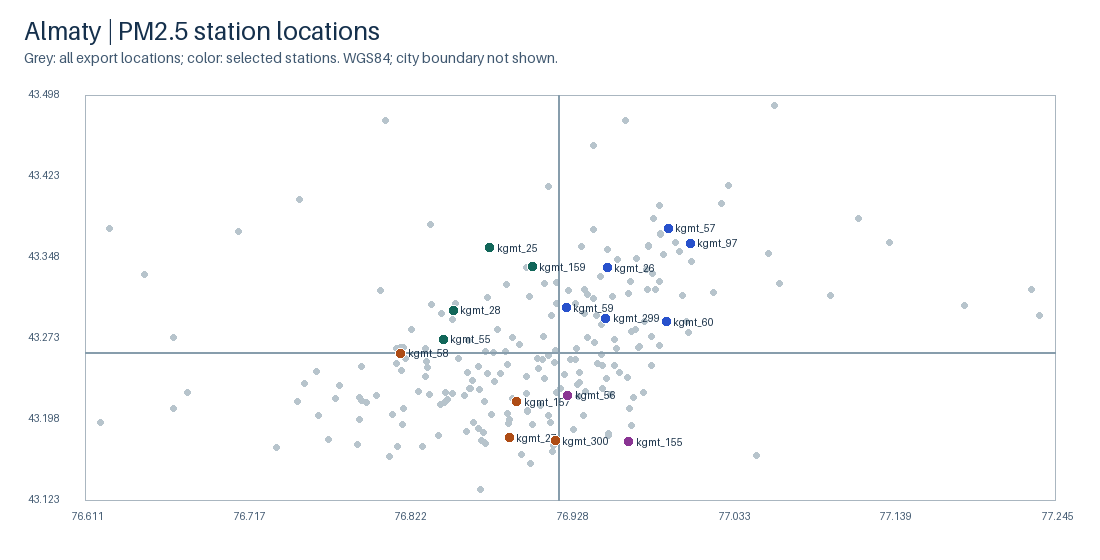

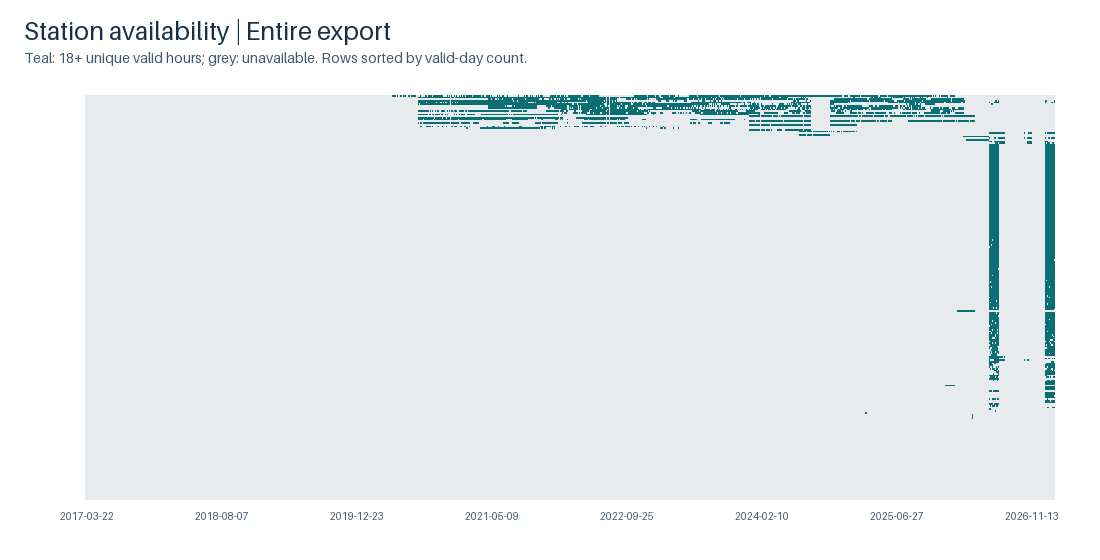

In [4]:
stats=[]
for st, rows in obs.dropna(subset=['day','station_id']).groupby('station_id'):
    first,last=rows.day.min(),rows.day.max()
    a=mat[st]
    stats.append(dict(station_id=st,first_observed=first,last_observed=last,
        months_observed=rows.day.dt.to_period('M').nunique(),
        longest_valid_run=int(a.groupby((~a).cumsum()).sum().max()),
        valid_days=int(a.sum()),fraction_full_calendar=a.mean(),
        fraction_observed_span=a.sum()/((last-first).days+1)))
s=meta.join(pd.DataFrame(stats).set_index('station_id'))
eligible=(s.sources.isin(['kgmt','kgmt_auto','kgmt;kgmt_auto'])&s.reg_city.eq('Almaty')&
    s.reg_operator.eq('KazHydroMet')&s.zone.notna()&s.valid_days.gt(0)&
    s.reg_distance_m.le(NEAR)&s.geo_distance_m.le(NEAR)).fillna(False)
s['eligible_primary_pool']=eligible
pool=sorted(s.index[eligible])
save(s.reset_index(),'station_completeness')
display(s.loc[pool,['sources','zone','valid_days','fraction_full_calendar','fraction_observed_span']].reset_index())
def fig(title, sub='', height=560):
    im=Image.new('RGB',(1100,height),'white')
    dr=ImageDraw.Draw(im)
    dr.text((24,15),title,fill='#15304c',font_size=25)
    dr.text((24,49),sub,fill='#405870',font_size=14)
    return im,dr
def png(im,name):
    im.save(OUT/(name+'.png')); display(im)
def map_plot(selected,name):
    im,dr=fig('Almaty | PM2.5 station locations','Grey: all export locations; color: selected stations. WGS84; city boundary not shown.')
    la0,la1=pos.lat.min()-.01,pos.lat.max()+.01
    lo0,lo1=pos.lon.min()-.01,pos.lon.max()+.01
    def xy(la,lo): return 85+(lo-lo0)/(lo1-lo0)*970,500-(la-la0)/(la1-la0)*405
    dr.rectangle((85,95,1055,500),outline='#aab6c0')
    for la in np.linspace(la0,la1,6):
        a,b=xy(la,lo0);dr.text((28,b-7),f'{la:.3f}',fill='#405870')
    for lo in np.linspace(lo0,lo1,7):
        a,b=xy(la0,lo);dr.text((a-13,b+10),f'{lo:.3f}',fill='#405870')
    for _,la,lo in records:
        a,b=xy(la,lo);dr.ellipse((a-3,b-3,a+3,b+3),fill='#b7c4cc')
    colors={'NE':'#2851cc','NW':'#116659','SE':'#8a3493','SW':'#ae4c15'}
    a,b=xy(LAT,LON)
    if 85<=a<=1055:dr.line((a,95,a,500),fill='#879dac',width=2)
    if 95<=b<=500:dr.line((85,b,1055,b),fill='#879dac',width=2)
    for st,row in s.loc[list(selected)].iterrows():
        a,b=xy(row.lat,row.lon)
        dr.ellipse((a-5,b-5,a+5,b+5),fill=colors[row.zone],outline='white')
        dr.text((a+7,b-6),st,fill='#183047')
    png(im,name)
def tile(a):
    return Image.fromarray(np.where(a[:,:,None], [11,110,114], [231,235,238]).astype('uint8'))
def time_labels(dr,y):
    for i in np.linspace(0,len(calendar)-1,8,dtype=int):
        dr.text((60+i/(len(calendar)-1)*945,y),str(calendar[i].date()),fill='#405870')
map_plot(pool,'station_map')
im,dr=fig('Station availability | Entire export','Teal: 18+ unique valid hours; grey: unavailable. Rows sorted by valid-day count.')
im.paste(tile(mat[s.valid_days.sort_values(ascending=False).index].to_numpy().T)
         .resize((970,405),Image.Resampling.NEAREST),(85,95))
time_labels(dr,510);png(im,'availability_heatmap')


### 4. Candidate networks and chronological split

A ranks posts by individual completeness. B maximizes shared complete calibration days under sector constraints. C maximizes shared days without sector constraints. E explores historical splits using availability. The main feasibility split starts on 1 January 2024. Historical alternatives require at least 90 complete days and at least 10 winter and summer days in each period.


,n,any_n_or_more_days
0,6,365
1,8,46
2,10,0
3,12,0


,network,station_ids,zone_counts,all_days,cal_days,test_days,all_first,all_last
0,8A,kgmt_155;kgmt_159;kgmt_26;kgmt_27;kgmt_56;kgmt...,"{""NE"": 4, ""NW"": 1, ""SE"": 2, ""SW"": 1}",154,154,0,2021-03-26,2023-08-09
1,8B,kgmt_26;kgmt_27;kgmt_28;kgmt_56;kgmt_58;kgmt_5...,"{""NE"": 4, ""NW"": 1, ""SE"": 1, ""SW"": 2}",264,264,0,2020-07-15,2022-07-07
2,8C,kgmt_26;kgmt_27;kgmt_28;kgmt_56;kgmt_58;kgmt_5...,"{""NE"": 4, ""NW"": 1, ""SE"": 1, ""SW"": 2}",264,264,0,2020-07-15,2022-07-07
3,10A,kgmt_155;kgmt_159;kgmt_26;kgmt_27;kgmt_28;kgmt...,"{""NE"": 4, ""NW"": 2, ""SE"": 2, ""SW"": 2}",122,122,0,2021-03-26,2022-07-04
4,10B,kgmt_155;kgmt_157;kgmt_26;kgmt_27;kgmt_28;kgmt...,"{""NE"": 4, ""NW"": 1, ""SE"": 2, ""SW"": 3}",155,155,0,2021-03-25,2022-07-04
5,10C,kgmt_155;kgmt_157;kgmt_26;kgmt_27;kgmt_28;kgmt...,"{""NE"": 4, ""NW"": 1, ""SE"": 2, ""SW"": 3}",155,155,0,2021-03-25,2022-07-04
6,12A,kgmt_155;kgmt_157;kgmt_159;kgmt_26;kgmt_27;kgm...,"{""NE"": 5, ""NW"": 2, ""SE"": 2, ""SW"": 3}",37,37,0,2022-03-27,2022-07-04
7,12B,kgmt_155;kgmt_157;kgmt_159;kgmt_26;kgmt_27;kgm...,"{""NE"": 5, ""NW"": 2, ""SE"": 2, ""SW"": 3}",73,73,0,2021-03-26,2021-08-11
8,12C,kgmt_155;kgmt_157;kgmt_159;kgmt_26;kgmt_27;kgm...,"{""NE"": 5, ""NW"": 2, ""SE"": 2, ""SW"": 3}",73,73,0,2021-03-26,2021-08-11
9,6A,kgmt_155;kgmt_26;kgmt_27;kgmt_56;kgmt_59;kgmt_60,"{""NE"": 3, ""SE"": 2, ""SW"": 1}",303,303,0,2021-03-25,2023-09-17


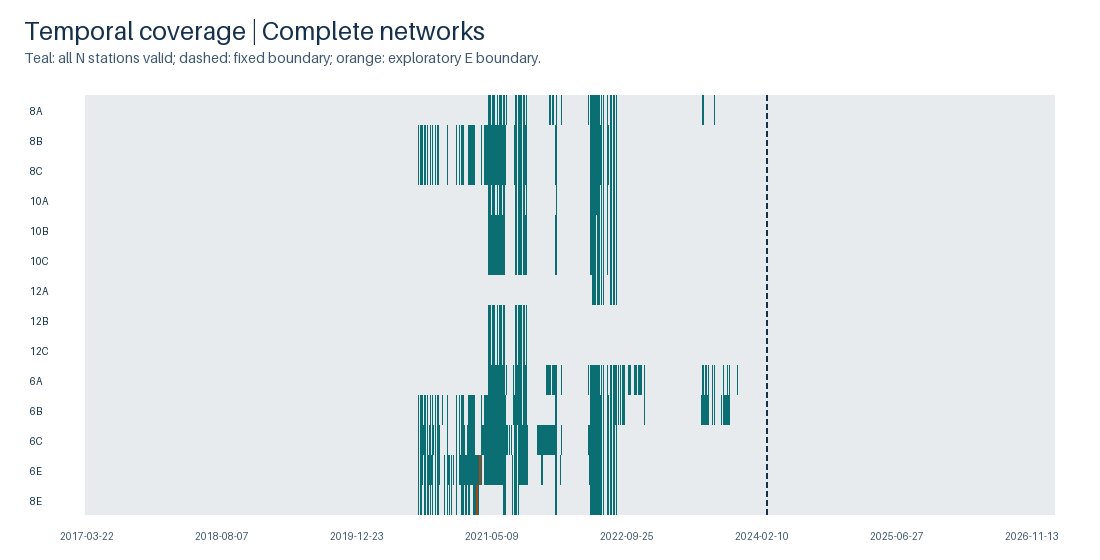

In [5]:
early=calendar<CUT
seasons=np.array(['DJF' if m in [12,1,2] else 'JJA' if m in [6,7,8] else 'MAM' if m in [3,4,5] else 'SON' for m in calendar.month])
blocked={frozenset((a,b)) for a,b in zip(near.id_a,near.id_b)}
def compatible(st): return all(frozenset(p) not in blocked for p in combinations(st,2))
def zones(st): return Counter(s.loc[list(st),'zone'])
def balanced(z): return len(z)>=3 and sum(v>=2 for v in z.values())>=2
zone_lookup=s.zone.to_dict()
packed={st:int.from_bytes(np.packbits(mat.loc[early,st].to_numpy()).tobytes(),'big') for st in pool}
ranked=sorted(pool,key=lambda st:(-packed[st].bit_count(),st))
fullest=[]
for st in ranked:
    if compatible(fullest+[st]): fullest.append(st)
def search(n):
    best={}
    for st in combinations(pool,n):
        if not compatible(st): continue
        m=packed[st[0]]
        for k in st[1:]: m &= packed[k]
        z=Counter(zone_lookup[k] for k in st)
        score=(m.bit_count(),len(z),-max(z.values()),sum(packed[k].bit_count() for k in st))
        for label in ('B','C') if balanced(z) else ('C',):
            if label not in best or score>best[label][0]:best[label]=(score,st)
    a=tuple(sorted(fullest[:n])) if len(fullest)>=n else ()
    return [(n,'A',a)]+[(n,r,best.get(r,(None,()))[1]) for r in ('B','C')]
assert len(pool)<=22, 'The candidate pool is too large for exhaustive search.'
nets=[net for n in SIZES for net in search(n)]
def overlap(st,h=18): return matrices[h][list(st)].all(axis=1).to_numpy()
def season_counts(mask): return {k:int((mask&(seasons==k)).sum()) for k in ['DJF','MAM','JJA','SON']}
def span(mask):
    d=calendar[mask]
    return (str(d[0].date()),str(d[-1].date())) if len(d) else ('','')
def adequate(mask,cut):
    a,b=mask&(calendar<cut),mask&(calendar>=cut)
    sa,sb=season_counts(a),season_counts(b)
    return min(a.sum(),b.sum())>=MIN_DAYS and min(sa['DJF'],sa['JJA'],sb['DJF'],sb['JJA'])>=MIN_SEASON
if not any(st and r=='B' and adequate(overlap(st),CUT) for _,r,st in nets): nets+=search(6)
late_count=mat.loc[~early,pool].sum(axis=1)
upper=pd.DataFrame([dict(n=n,any_n_or_more_days=int(late_count.ge(n).sum()))
                    for n in (6,8,10,12)])
save(upper,'fixed_test_upper_bounds');display(upper)
exploratory={}; exist=[]
arr=mat[pool].to_numpy()
winter=seasons=='DJF'; summer=seasons=='JJA'
for n in (6,*SIZES):
    best=None; count=0
    for ji in combinations(range(len(pool)),n):
        st=tuple(pool[i] for i in ji)
        z=Counter(zone_lookup[k] for k in st)
        if not balanced(z) or not compatible(st): continue
        ix=np.flatnonzero(arr[:,ji].all(axis=1))
        if len(ix)<2*MIN_DAYS: continue
        w=np.cumsum(winter[ix])[:-1]; u=np.cumsum(summer[ix])[:-1]
        j=np.arange(1,len(ix))
        ok=(np.minimum(j,len(ix)-j)>=MIN_DAYS)&(np.minimum.reduce([
            w,winter[ix].sum()-w,u,summer[ix].sum()-u])>=MIN_SEASON)
        if not ok.any():continue
        count+=1
        score=np.where(ok,np.minimum(j,len(ix)-j),0)
        jj=int(score.argmax())
        item=((int(score[jj]),len(ix),len(z)),calendar[ix[jj+1]],st)
        if best is None or item[0]>best[0]:best=item
    exist.append(dict(n=n,balanced_networks_passing_any_cut=count))
    if best:
        _,cut,st=best
        exploratory[f'{n}E']=cut
        nets.append((n,'E',st))
save(pd.DataFrame(exist),'exploratory_existence')
cand_rows=[]; split_rows=[]; masks={}; sensitivity=[]
for n,r,st in nets:
    k=f'{n}{r}'
    row=dict(network=k,station_ids=';'.join(st),n=n,variant=r,status='evaluated' if st else 'unavailable')
    cand_rows.append(row)
    if not st: continue
    m=masks[k]=overlap(st)
    row['zone_counts']=json.dumps(dict(zones(st)),sort_keys=True)
    row['balanced']=balanced(zones(st))
    cut_for_net=exploratory.get(k,CUT)
    row['test_start']=str(cut_for_net.date())
    row['fixed_screen']=adequate(m,CUT)
    train=calendar<cut_for_net
    for name,v in [('all',m),('cal',m&train),('test',m&~train)]:
        row[name+'_days']=int(v.sum())
        row[name+'_first'],row[name+'_last']=span(v)
        row.update({f'{name}_{k}':v for k,v in season_counts(v).items()})
    for h in HOURS:
        v=overlap(st,h)
        sensitivity.append((k,h,int(v.sum()),int((v&train).sum()),int((v&~train).sum())))
    for cut in pd.date_range(calendar[0],calendar[-1],freq='MS').union(pd.DatetimeIndex([CUT])):
        a,b=m&(calendar<cut),m&(calendar>=cut)
        sa,sb=season_counts(a),season_counts(b)
        split_rows.append((k,str(cut.date()),cut==CUT,int(a.sum()),int(b.sum()),
            sa['DJF'],sa['JJA'],sb['DJF'],sb['JJA'],int(min(a.sum(),b.sum())),adequate(m,cut)))
cand=pd.DataFrame(cand_rows)
splits=pd.DataFrame(split_rows,columns=['network','test_start','fixed','cal_days','test_days','cal_DJF','cal_JJA','test_DJF','test_JJA','min_days','passes'])
save(cand,'candidate_networks')
save(splits,'split_monthly_scan')
save(pd.DataFrame(sensitivity,columns=['network','min_hours','all_days','cal_days','test_days']),'completeness_sensitivity')
display(cand[[k for k in ['network','station_ids','zone_counts','all_days','cal_days','test_days','all_first','all_last'] if k in cand]])
if masks:
    im,dr=fig('Temporal coverage | Complete networks','Teal: all N stations valid; dashed: fixed boundary; orange: exploratory E boundary.')
    im.paste(tile(np.stack(list(masks.values()))).resize((970,30*len(masks)),Image.Resampling.NEAREST),(85,95))
    for i,k in enumerate(masks): dr.text((30,105+30*i),k,fill='#15304c')
    xx=85+int(970*early.mean())
    for y in range(95,95+30*len(masks),9): dr.line((xx,y,xx,y+5),fill='#15304c',width=2)
    for i,k in enumerate(masks):
        if k in exploratory:
            col=85+int(970*(calendar<exploratory[k]).mean())
            dr.line((col,95+30*i,col,124+30*i),fill='#a24716',width=2)
    time_labels(dr,110+30*len(masks));png(im,'temporal_coverage')


### 5. Operational reference and thresholds

The primary reference is the mean across all selected stations on complete days. Compare it with an equally weighted sector mean. A concentration strictly above 15 or 35 micrograms per cubic metre is an exceedance.


In [6]:
levels=[]; rows=[]; qs=[]
for n,r,st in nets:
    if not st:continue
    k=f'{n}{r}'
    v=pm.loc[masks[k],list(st)]
    z=zones(st)
    zone=pd.concat([v[[j for j in st if zone_lookup[j]==q]].mean(axis=1) for q in sorted(z)],axis=1).mean(axis=1)
    frame=pd.DataFrame({'network':k,'day':v.index,'station_mean':v.mean(axis=1).to_numpy(),'zone_mean':zone.to_numpy()})
    assert frame[['station_mean','zone_mean']].notna().all().all()
    levels.append(frame)
    cut_for_net=exploratory.get(k,CUT)
    for label,f in [('all',frame),('calibration',frame[frame.day<cut_for_net]),('test',frame[frame.day>=cut_for_net])]:
        for method in ['station_mean','zone_mean']:
            for q in [0,.05,.25,.5,.75,.95,1]:
                qs.append((k,label,method,q,f[method].quantile(q)))
        for t in [35,15]:
            a,b=f.station_mean.gt(t),f.zone_mean.gt(t)
            rows.append((k,label,t,len(f),int(a.sum()),int((~a).sum()),int(b.sum()),int((~b).sum()),
                         int((a&~b).sum()),int((~a&b).sum())))
ref=pd.concat(levels,ignore_index=True) if levels else pd.DataFrame()
thr=pd.DataFrame(rows,columns=['network','period','threshold','days','station_above','station_below_or_equal','zone_above',
    'zone_below_or_equal','station_above_zone_below','station_below_zone_above'])
save(ref,'reference_daily');save(thr,'threshold_counts')
save(pd.DataFrame(qs,columns=['network','period','aggregation','quantile','pm25']),'reference_quantiles')
display(thr[thr.period.ne('all')])


,network,period,threshold,days,station_above,station_below_or_equal,zone_above,zone_below_or_equal,station_above_zone_below,station_below_zone_above
2,8A,calibration,35,154,20,134,22,132,0,2
3,8A,calibration,15,154,79,75,77,77,4,2
4,8A,test,35,0,0,0,0,0,0,0
5,8A,test,15,0,0,0,0,0,0,0
8,8B,calibration,35,264,72,192,80,184,0,8
9,8B,calibration,15,264,190,74,189,75,6,5
10,8B,test,35,0,0,0,0,0,0,0
11,8B,test,15,0,0,0,0,0,0,0
14,8C,calibration,35,264,72,192,80,184,0,8
15,8C,calibration,15,264,190,74,189,75,6,5


### 6. Feasibility findings and export


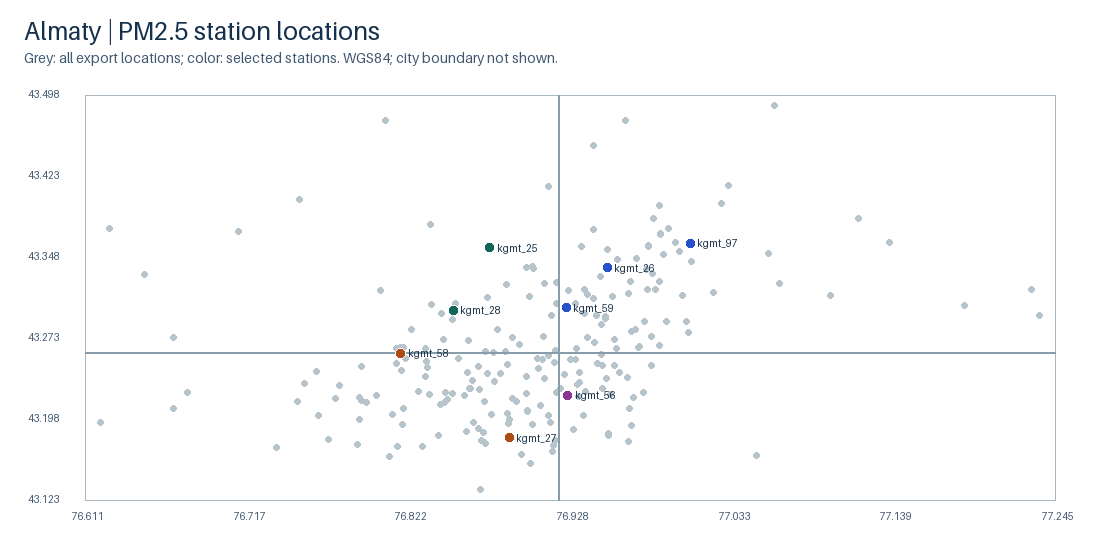

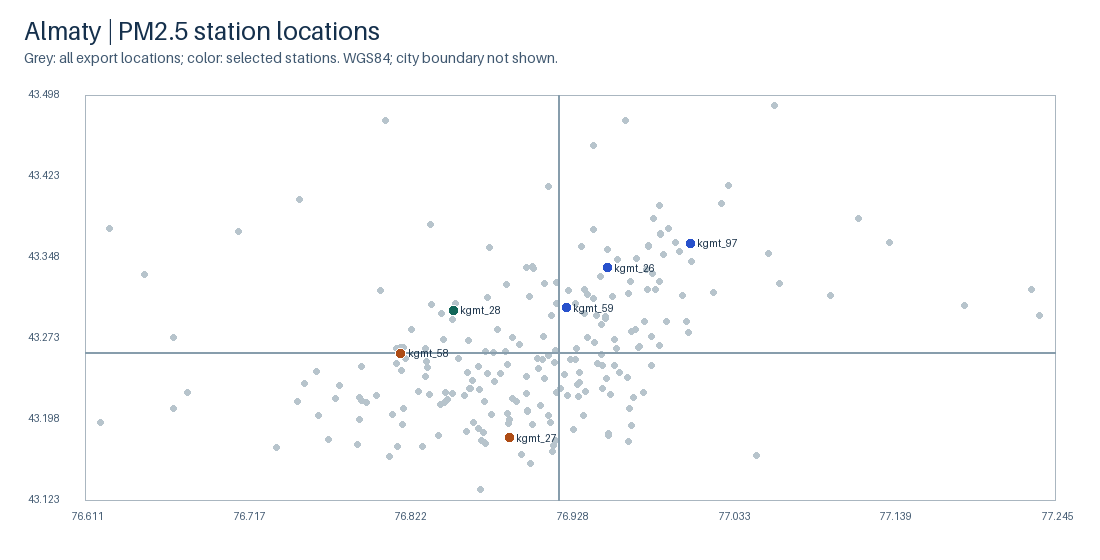

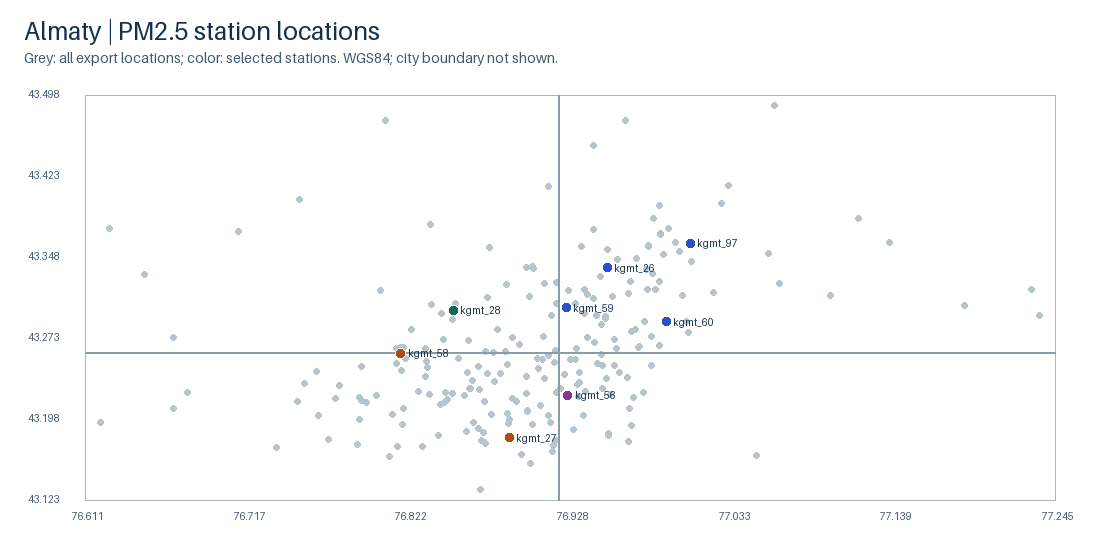

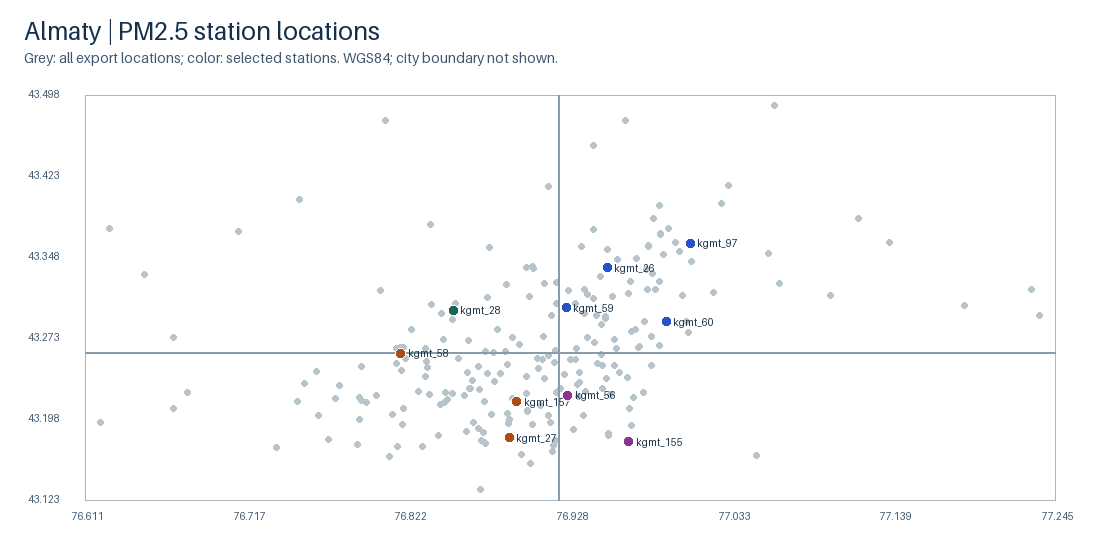

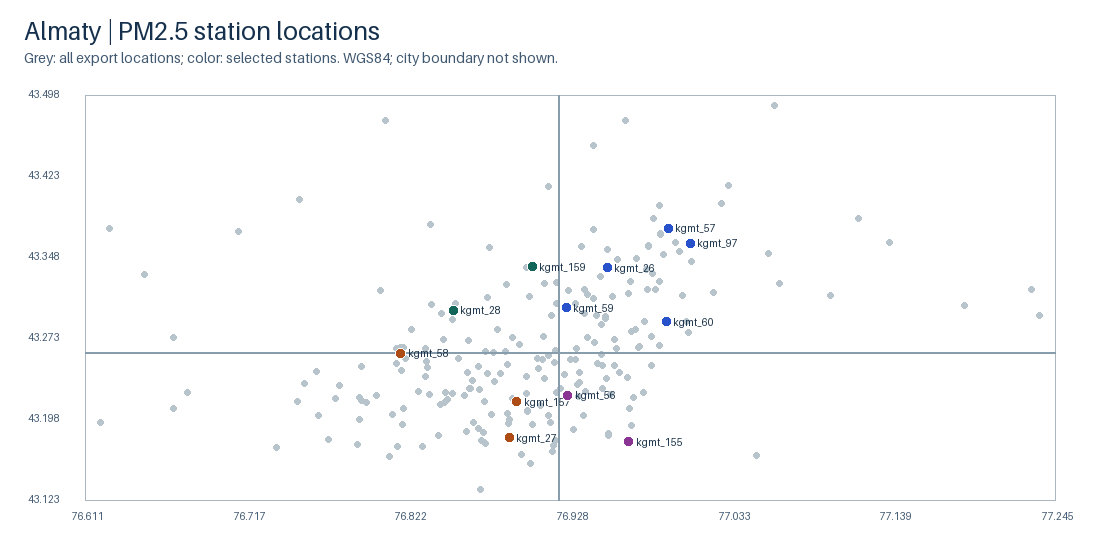

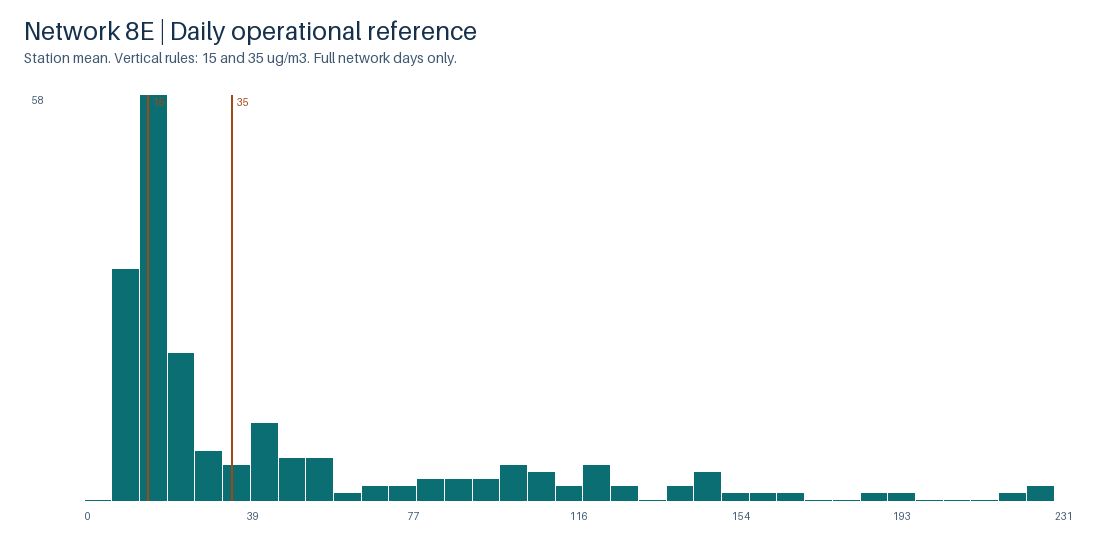

# Data Feasibility Study for Almaty

**NO-GO for the main design**. Candidate: **8B**. Station IDs: kgmt_26;kgmt_27;kgmt_28;kgmt_56;kgmt_58;kgmt_59;kgmt_60;kgmt_97.
Calendar screen: False. Class balance screen at 35: False.
Calibration precedes 2024-01-01. Test begins on that date.
**CONDITIONAL GO for a separate historical design: 6E, 8E**



CONDITIONAL GO for a separate historical design: 6E, 8E

,network,test_start,station_ids,cal_days,test_days
13,8E,2021-02-13,kgmt_25;kgmt_26;kgmt_27;kgmt_28;kgmt_56;kgmt_5...,92,101
12,6E,2021-02-22,kgmt_26;kgmt_27;kgmt_28;kgmt_58;kgmt_59;kgmt_97,151,207


NO-GO for the main design | candidate: 8B | archive: /content/almaty_pm25_outputs.zip


In [7]:
choices=cand[cand.variant.eq('B')&cand.status.eq('evaluated')].sort_values(['fixed_screen','cal_days','n'],ascending=False) if masks else cand.iloc[:0]
main_choices=choices[choices.n.isin(SIZES)]
chosen=main_choices.iloc[0] if len(main_choices) else None
k=chosen.network if chosen is not None else None
t=thr[thr.network.eq(k)&thr.threshold.eq(35)&thr.period.ne('all')]
class_ok=len(t)==2 and t[['station_above','station_below_or_equal']].ge(MIN_CLASS).all().all()
time_ok=bool(chosen.fixed_screen) if chosen is not None else False
alt=(splits[splits.passes&~splits.fixed].sort_values(['min_days','test_start'],ascending=[False,True])
     .drop_duplicates('network'))
decision='CONDITIONAL GO for the main design' if time_ok and class_ok else 'NO-GO for the main design'
ep=cand[cand.variant.eq('E')].sort_values('n',ascending=False)
for row in ep.itertuples():
    map_plot(row.station_ids.split(';'),f'network_{row.network}_map')
e35=thr[thr.network.isin(ep.network)&thr.threshold.eq(35)&thr.period.ne('all')]
e_ok=[name for name,g in e35.groupby('network') if len(g)==2 and
      g[['station_above','station_below_or_equal']].ge(MIN_CLASS).all().all()]
ep_summary=('CONDITIONAL GO for a separate historical design: '+', '.join(e_ok)
            if e_ok else 'Historical alternatives did not pass the class screen at 35.')

if k:
    for n in SIZES:
        b=choices[choices.n.eq(n)]
        if not b.empty: map_plot(b.iloc[0].station_ids.split(';'),f'network_{n}B_map')
    a=ref.loc[ref.network.eq(ep.iloc[0].network if len(ep) else k),'station_mean'].to_numpy()
    plot_id=ep.iloc[0].network if len(ep) else k
    if len(a):
        im,dr=fig(f'Network {plot_id} | Daily operational reference','Station mean. Vertical rules: 15 and 35 ug/m3. Full network days only.')
        vmax=max(36,a.max())
        h,_=np.histogram(a,bins=np.linspace(0,vmax,36))
        for j,y in enumerate(h):
            x0=85+j*970/len(h);x1=85+(j+1)*970/len(h)
            dr.rectangle((x0,500-y*405/max(h),x1-2,500),fill='#0b6e72')
        for v in (15,35):
            xx=85+970*v/vmax;dr.line((xx,95,xx,500),fill='#a24716',width=2)
            dr.text((xx+5,96),str(v),fill='#a24716')
        for v in np.linspace(0,vmax,7): dr.text((85+970*v/vmax,510),f'{v:.0f}',fill='#405870')
        dr.text((32,94),str(max(h)),fill='#405870')
        png(im,'reference_distribution')
pick=chosen.station_ids if chosen is not None else '—'
report=f'''# Data Feasibility Study for Almaty

**{decision}**. Candidate: **{k or "none"}**. Station IDs: {pick}.
Calendar screen: {time_ok}. Class balance screen at 35: {class_ok}.
Calibration precedes {CUT.date()}. Test begins on that date.
**{ep_summary}**

## Data quality

{md(quality)}

{md(sources)}

There are {len(pool)} KazHydroMet identifiers in the validated candidate pool.
Coordinate matches are screening evidence. Exact physical site identity requires independent verification.
The hash manifest records the local input snapshot. Upstream filtering can affect completeness and extremes.

## Candidate networks and seasons

{md(cand)}

Historical configurations use availability over the full calendar. Independent confirmation requires separate observations.
The table below bounds complete test days from 2024 by allowing station composition to vary across days.

{md(upper)}

### Exploratory historical screening

{md(pd.DataFrame(exist))}

{md(alt) if not alt.empty else "No alternative monthly cut passes the screening rules."}

## Threshold analysis

{md(thr)}

The daily average of the full network defines the operational reference. Equal sector weights provide a sensitivity comparison.
See the supporting CSVs for daily values, quantiles and completeness at 12, 18 and 20 valid hours.

## Outage evaluation

The pilot section evaluates station loss and full sector loss at matched expected publication availability.
'''
(OUT/'feasibility_report.md').write_text(report,encoding='utf-8')
display(Markdown(report.split('## Data quality')[0]+'\n\n'+ep_summary))
display(ep[['network','test_start','station_ids','cal_days','test_days']] if len(ep) else ep)

assert mat.shape==(len(calendar),len(ids))
assert int(mat.to_numpy().sum())==int(daily.valid_18.sum())
assert (thr.station_above+thr.station_below_or_equal).eq(thr.days).all()
archive=shutil.make_archive(str(OUT.parent/'almaty_pm25_outputs'),'zip',OUT)
print(f'{decision} | candidate: {k} | archive: {archive}')
if DOWNLOAD_ZIP:
    from google.colab import files
    files.download(archive)


## Retrospective pilot

The pilot uses the files generated by the feasibility analysis above.


### Pilot protocol

Use eight KazHydroMet posts, a minimum of 18 valid hours and a chronological split with test starting on 13 February 2021. The operational reference is the mean of eight valid station means. The primary threshold is 15 micrograms per cubic metre and the sensitivity threshold is 35. Compare station count with sector count followed by station count. Give equal mass to each outage size from one to three posts and equal mass to masks within each size. Set boundary probabilities analytically to match expected availability at 60%, 75% and 90%. Evaluate 75% as the primary operating point. Estimate paired intervals using 5,000 bootstrap samples of calendar days with seed 20261113. A seven-observed-day block analysis checks sensitivity to dependence.


In [8]:
from pathlib import Path
from itertools import combinations
import hashlib, json, os, shutil
import numpy as np
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    def display(x): print(x.to_string(index=False))
DATA=Path(os.getenv('ALMATY_FEASIBILITY','/content/almaty_outputs'))
OUT=Path(os.getenv('ALMATY_PILOT_OUTPUT','/content/pilot_outputs'))
DOWNLOAD_ZIP=False
OUT.mkdir(parents=True,exist_ok=True)
IDS=[f'kgmt_{i}' for i in [25,26,27,28,56,58,59,97]]
CUT='2021-02-13'
SEED=20261113
BOOT=5000
TARGETS=(.60,.75,.90)
inputs=[DATA/'station_daily_qc.csv',DATA/'station_completeness.csv']
daily=pd.read_csv(inputs[0],parse_dates=['day'])
meta=pd.read_csv(inputs[1]).set_index('station_id').loc[IDS]
assert meta.location_count.eq(1).all() and (~meta.historical_period).all()
assert meta[['reg_distance_m','geo_distance_m']].eq(0).all().all()
zones=np.char.add(np.where(meta.lat>=43.26,'N','S'),np.where(meta.lon>=76.92,'E','W'))
assert np.array_equal(zones,meta.zone)
meta[['lat','lon','zone','sources']].to_csv(OUT/'station_verification.csv')
vals=daily[daily.station_id.isin(IDS)&daily.hours.ge(18)].pivot(index='day',columns='station_id',values='pm25')[IDS].dropna()
cal=vals.index<CUT
assert (len(vals),int(cal.sum()))==(193,92)
unique_zones=np.unique(zones)
month=vals.index.month
season=np.select([np.isin(month,[12,1,2]),np.isin(month,[3,4,5]),np.isin(month,[6,7,8])],['DJF','MAM','JJA'],default='SON')
refmean=vals.to_numpy().mean(axis=1)
zonemean=np.column_stack([vals.to_numpy()[:,zones==z].mean(axis=1) for z in unique_zones]).mean(axis=1)


### Exact outage masks and calibration

Construct the mask inventory and set the probability of publication at each rule's calibration boundary.


In [9]:
catalog=[]
for scenario in ['random','zone']:
    if scenario=='random':
        drops=[drop for n in (1,2,3) for drop in combinations(range(8),n)]
    else:
        drops=[tuple(np.flatnonzero(zones==z)) for z in unique_zones]
    sizes=np.array([len(d) for d in drops])
    weights=np.array([1/(3*np.count_nonzero(sizes==n)) for n in sizes])
    active=np.array([[i not in drop for i in range(8)] for drop in drops])
    nactive=active.sum(axis=1)
    nz=np.array([len(set(zones[row])) for row in active])
    assert np.isclose(weights.sum(),1)
    avg=vals.to_numpy()@active.T/nactive
    for j,drop in enumerate(drops):
        catalog.append(dict(scenario=scenario,mask_id=j,dropped=';'.join(IDS[i] for i in drop),
                            size=sizes[j],weight=weights[j],active_stations=nactive[j],active_zones=nz[j]))
    if scenario=='random': random_data=(avg,weights,sizes,nactive,nz)
    else: zone_data=(avg,weights,sizes,nactive,nz)
pd.DataFrame(catalog).to_csv(OUT/'outage_masks.csv',index=False)
def fit_policy(scores,weights,target):
    remaining=target
    for boundary in sorted(set(scores),reverse=True):
        mass=weights[scores==boundary].sum()
        if remaining<=mass+1e-12:
            p=float(np.clip(remaining/mass,0,1))
            return np.where(scores>boundary,1,np.where(scores==boundary,p,0)),boundary,p
        remaining-=mass
    raise ValueError('Coverage target outside weighted support')
policies=[]
frozen={}
for scenario,data in [('random',random_data),('zone',zone_data)]:
    avg,w,size,nactive,nz=data
    for target in TARGETS:
        for rule,score in [('A',nactive),('B',10*nz+nactive)]:
            pub,boundary,p=fit_policy(score,w,target)
            frozen[scenario,target,rule]=pub
            policies.append(dict(scenario=scenario,target=target,rule=rule,score_at_boundary=boundary,
                                 p_at_boundary=p,calibration_availability=float(w@pub)))
pd.DataFrame(policies).to_csv(OUT/'frozen_policies.csv',index=False)


### Calibration and test results

Integrate over weighted masks and boundary publication probabilities. Report expected counts, selective error rates and paired differences by period and season.


In [10]:
def day_counts(reference,above,pub_weights):
    p=above@pub_weights
    q=(~above)@pub_weights
    return np.stack([q*reference,p*reference,p*~reference,q*~reference],axis=1)
def safe(a,b):
    with np.errstate(invalid='ignore',divide='ignore'):
        return np.where(b>0,a/b,np.nan)
def rate(a):
    fn,tp,fp,tn=np.moveaxis(a,-1,0)
    return np.stack([100*fn,safe(fn,fn+tp),safe(fp,fp+tn),fn+tp+fp+tn],axis=-1)
metric_names=['fn_per_100','selective_fnr','selective_fpr','availability']
def resample(n,block,rng):
    if block==1: return rng.integers(n,size=(BOOT,n))
    starts=rng.integers(n,size=(BOOT,int(np.ceil(n/block))))
    return ((starts[:,:,None]+np.arange(block))%n).reshape(BOOT,-1)[:,:n]
rows=[]; effects=[]
for scenario,data in [('random',random_data),('zone',zone_data)]:
    avg,w,size,_,_=data
    for target in TARGETS:
        for threshold,ref_kind,reference in [(15,'station',refmean),(35,'station',refmean),(15,'zone',zonemean),(35,'zone',zonemean)]:
            actual=reference>threshold
            predicted=avg>threshold
            for severity in ['all',1,2,3]:
                mw=w if severity=='all' else (w*(size==severity))/(w[size==severity].sum())
                d={r:day_counts(actual,predicted,frozen[scenario,target,r]*mw) for r in ('A','B')}
                for partition,period in [('calibration',cal),('test',~cal)]:
                    for seas in ['all','DJF','MAM','JJA','SON']:
                        keep=period if seas=='all' else period&(season==seas)
                        n=int(keep.sum())
                        tags=dict(scenario=scenario,target=target,threshold=threshold,reference=ref_kind,
                                  severity=severity,partition=partition,season=seas)
                        for r in ('A','B'):
                            total=d[r][keep].sum(axis=0)
                            result=rate(total/n) if n else [np.nan]*4
                            fn,tp,fp,tn=total
                            rows.append(dict(tags,rule=r,days=n,reference_above=int(actual[keep].sum()),
                                reference_below=int((~actual[keep]).sum()),fn=fn,tp=tp,fp=fp,tn=tn,
                                fnr_denominator=fn+tp,fpr_denominator=fp+tn,published=total.sum(),
                                abstained=n-total.sum(),abstention_rate=1-result[-1],
                                **dict(zip(metric_names,result))))
                        if partition!='test' or severity!='all' or not n: continue
                        a,b=d['A'][keep],d['B'][keep]
                        diff=rate(b.mean(axis=0))-rate(a.mean(axis=0))
                        assert abs(diff[-1])<=0.0001
                        for block in ([1,7] if seas=='all' and threshold==15 and target==.75 and ref_kind=='station' else [1]):
                            ix=resample(n,block,np.random.default_rng(SEED))
                            delta=rate(b[ix].mean(axis=1))-rate(a[ix].mean(axis=1))
                            for k,metric in enumerate(metric_names):
                                valid=delta[:,k][np.isfinite(delta[:,k])]
                                lo,hi=np.percentile(valid,[2.5,97.5]) if len(valid) else (np.nan,np.nan)
                                effects.append(dict(tags,block=block,metric=metric,b_minus_a=diff[k],
                                                    ci_low=lo,ci_high=hi,bootstrap_defined=len(valid)))
results=pd.DataFrame(rows)
ci=pd.DataFrame(effects)
results.to_csv(OUT/'pilot_metrics.csv',index=False)
ci.to_csv(OUT/'pilot_effects.csv',index=False)
primary=(results.partition.eq('test')&results.season.eq('all')&results.severity.eq('all')&
         results.target.eq(.75)&results.threshold.eq(15)&results.reference.eq('station'))
table=results.loc[primary,['scenario','rule','days','reference_above','fn','fnr_denominator','fn_per_100',
                           'selective_fnr','selective_fpr','published','abstained','availability']]
display(table.round(4))
main_ci=ci[(ci.season=='all')&(ci.target==.75)&(ci.threshold==15)&(ci.reference=='station')]
display(main_ci[['scenario','block','metric','b_minus_a','ci_low','ci_high']].round(4))
manifest=dict(seed=SEED,bootstrap_reps=BOOT,inputs={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in inputs})
(OUT/'pilot_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
archive=shutil.make_archive(str(OUT.parent/'almaty_pm25_pilot_outputs'),'zip',OUT)
if DOWNLOAD_ZIP:
    from google.colab import files
    files.download(archive)


,scenario,rule,days,reference_above,fn,fnr_denominator,fn_per_100,selective_fnr,selective_fpr,published,abstained,availability
330,random,A,101,68,4.5908,51.0,4.5453,0.0900,0.0795,75.75,25.25,0.75
331,random,B,101,68,4.8452,51.0,4.7973,0.0950,0.0808,75.75,25.25,0.75
1290,zone,A,101,68,3.6667,51.0,3.6304,0.0719,0.0572,75.75,25.25,0.75
1291,zone,B,101,68,3.6667,51.0,3.6304,0.0719,0.0572,75.75,25.25,0.75


,scenario,block,metric,b_minus_a,ci_low,ci_high
80,random,1,fn_per_100,0.2519,0.0481,0.4536
81,random,1,selective_fnr,0.0050,0.0010,0.0090
82,random,1,selective_fpr,0.0013,-0.0036,0.0065
83,random,1,availability,0.0000,-0.0000,0.0000
84,random,7,fn_per_100,0.2519,0.0666,0.4355
85,random,7,selective_fnr,0.0050,0.0012,0.0094
86,random,7,selective_fpr,0.0013,-0.0042,0.0073
87,random,7,availability,0.0000,-0.0000,0.0000
324,zone,1,fn_per_100,0.0000,0.0000,0.0000
325,zone,1,selective_fnr,0.0000,0.0000,0.0000


### Pilot interpretation

At 75% expected availability and the primary threshold, random loss yielded 4.55 and 4.80 false below-threshold reports per 100 test days for Rules A and B. The paired difference was 0.252 (95% interval 0.048 to 0.454). Full sector loss leaves three sectors in every mask, producing identical policies. The scope is the eight historical posts and the specified distributions.


## Results figures

This cell displays and exports the station map, the comparison at matched reporting availability, and the seasonal results.


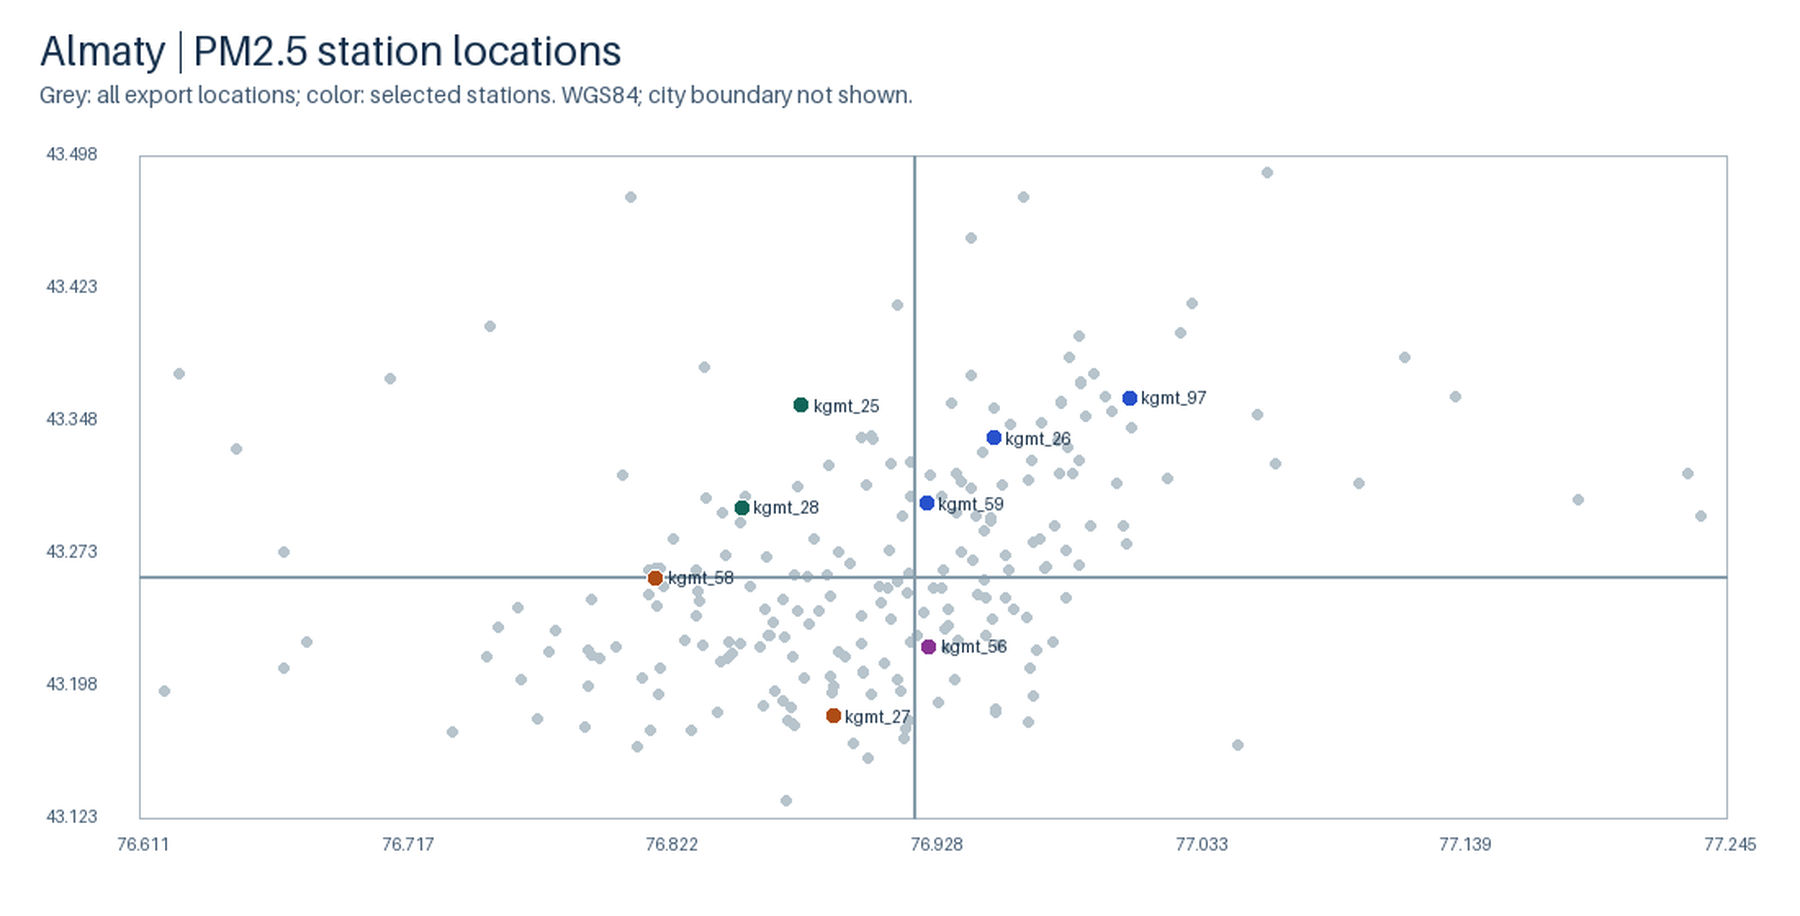

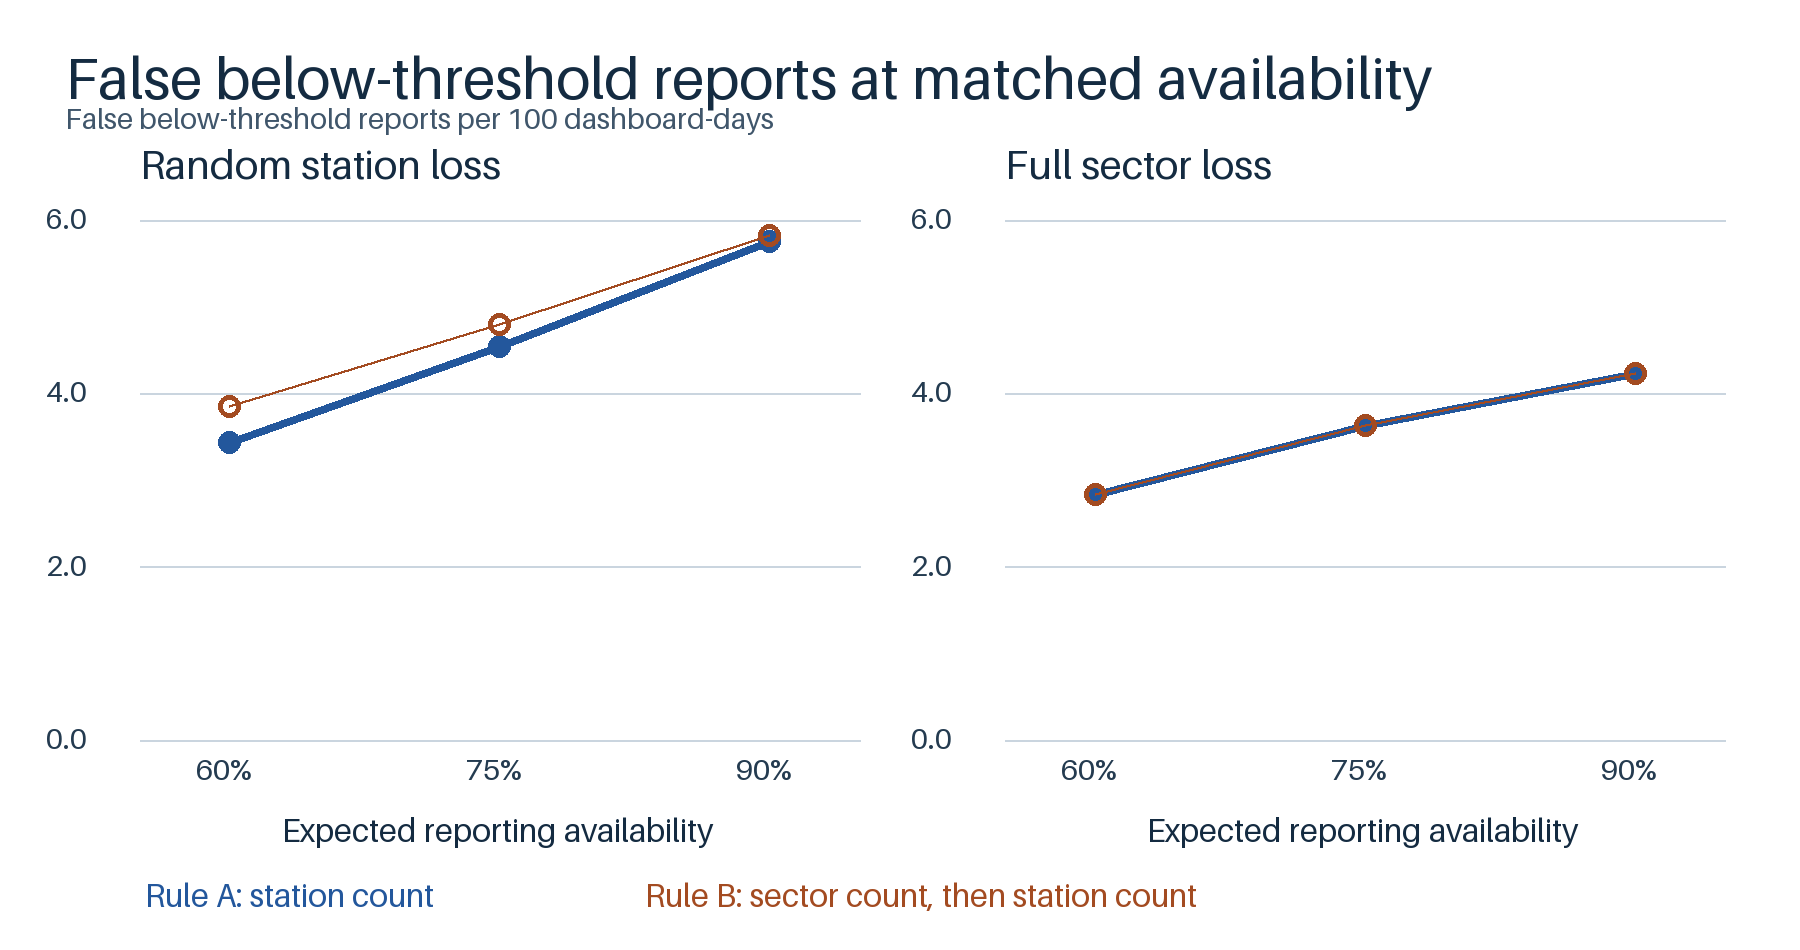

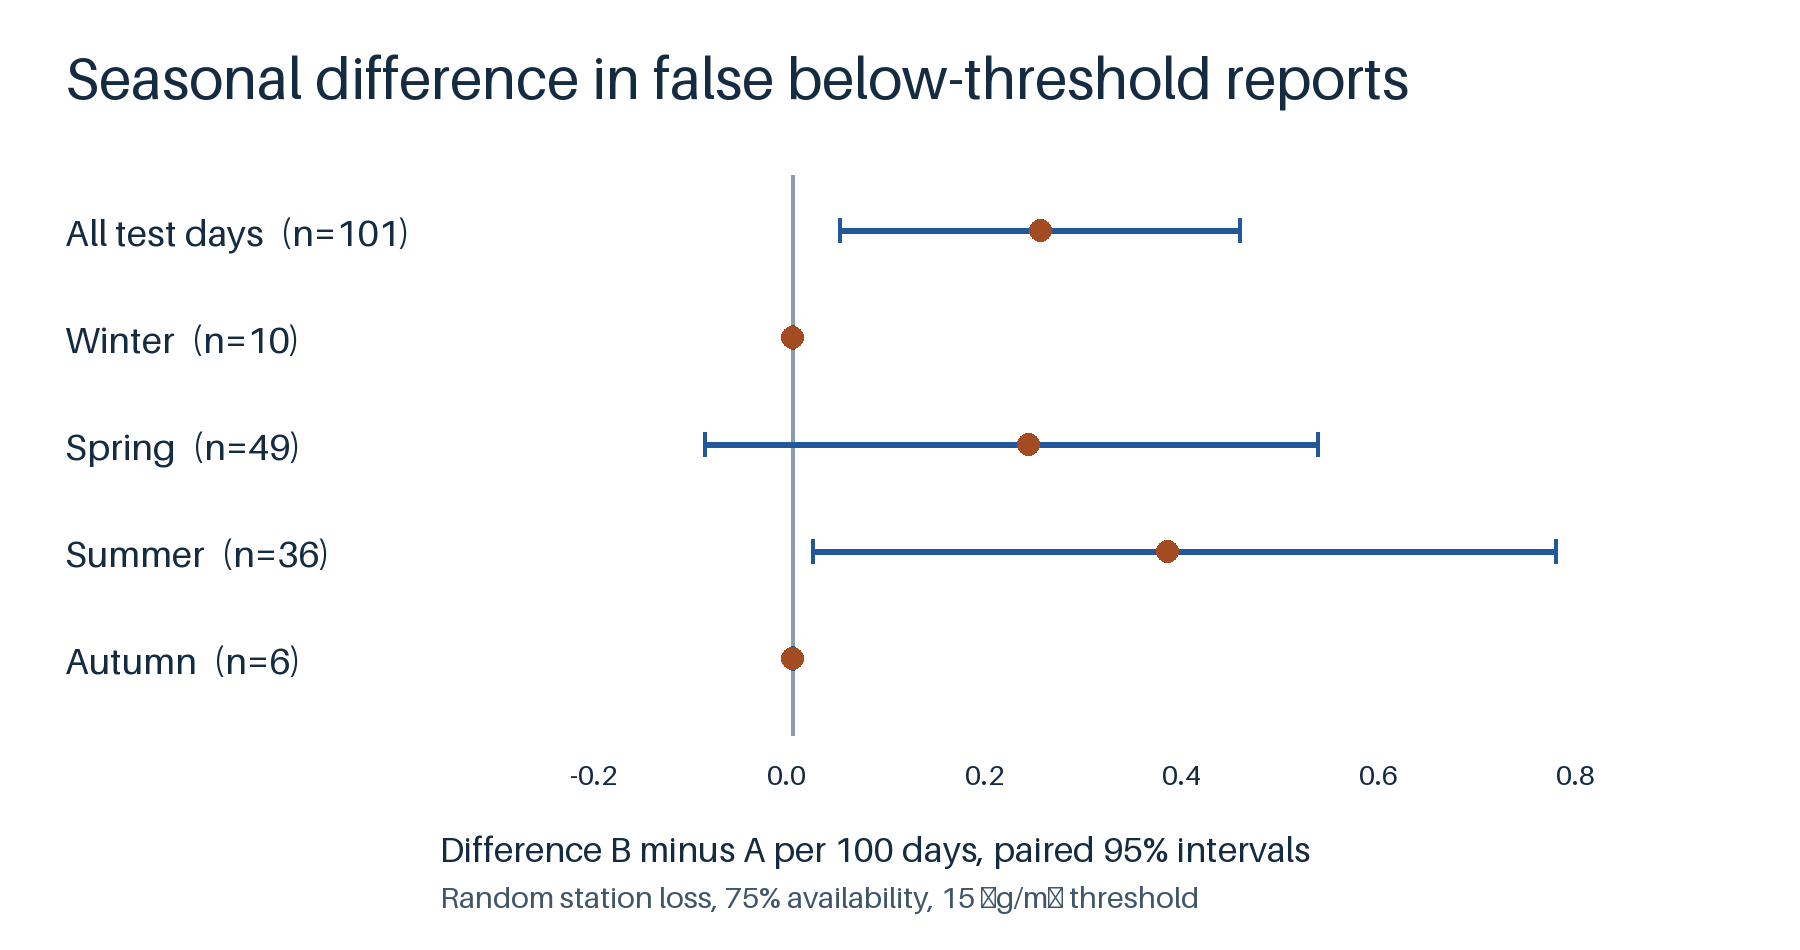

Figures saved: /content/almaty_results_figures.zip


In [11]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import numpy as np
import pandas as pd

FIGURES=Path(os.getenv('ALMATY_FIGURES','/content/results_figures'))
FIGURES.mkdir(parents=True,exist_ok=True)
def font(size):
    for family in ['DejaVuSerif.ttf','C:/Windows/Fonts/times.ttf']:
        try: return ImageFont.truetype(family,size)
        except OSError: continue
    return ImageFont.load_default(size=size)
def canvas(title,width=1800,height=950):
    im=Image.new('RGB',(width,height),'white')
    dr=ImageDraw.Draw(im)
    dr.text((65,42),title,font=font(58),fill='#142b41')
    return im,dr
def publish(im,name):
    im.save(FIGURES/(name+'.png'),dpi=(600,600))
    try:
        from IPython.display import display as show_image
    except ImportError:
        return
    show_image(im)
# Export the eight-post map from the feasibility section if present.
src=Path(os.getenv('ALMATY_OUTPUTS','/content/almaty_outputs'))/'network_8E_map.png'
if src.is_file():
    im=Image.open(src)
    publish(im.resize((1800,916),Image.Resampling.LANCZOS),'fig03_station_map')

# Risk and availability points under identical weighted outage catalogs.
frame=results[(results.partition=='test')&(results.severity=='all')&
              (results.season=='all')&(results.threshold==15)&(results.reference=='station')]
im,dr=canvas('False below-threshold reports at matched availability')
colors={'A':'#23579c','B':'#a34b21'}
for panel,scenario in enumerate(['random','zone']):
    x0=140+panel*865; x1=x0+720; y0,y1=740,220
    f=frame[frame.scenario==scenario]
    ymax=max(6,float(np.ceil(f.fn_per_100.max())))
    def xy(c,r): return x0+(c-.55)/.40*(x1-x0), y0-r/ymax*(y0-y1)
    dr.text((x0,140),['Random station loss','Full sector loss'][panel],font=font(40),fill='#142b41')
    for v in np.linspace(0,ymax,4):
        x,y=xy(.55,v);dr.line((x,y,x1,y),fill='#cad5df',width=2)
        dr.text((x0-94,y-20),f'{v:.1f}',font=font(29),fill='#243b50')
    for target in (.60,.75,.90):
        x,y=xy(target,0);dr.text((x-34,y+10),f'{target:.0%}',font=font(30),fill='#243b50')
    for rule in ['A','B']:
        subset=f[f.rule==rule].sort_values('target')
        points=[xy(a,b) for a,b in zip(subset.target,subset.fn_per_100)]
        dr.line(points,fill=colors[rule],width=8 if rule=='A' else 3)
        for x,y in points:
            dr.ellipse((x-11,y-11,x+11,y+11),outline=colors[rule],width=5,
                       fill=colors[rule] if rule=='A' else None)
    dr.text((x0+142,810),'Expected reporting availability',font=font(32),fill='#142b41')
dr.text((65,100),'False below-threshold reports per 100 dashboard-days',font=font(29),fill='#40566b')
dr.text((145,875),'Rule A: station count',font=font(32),fill=colors['A'])
dr.text((645,875),'Rule B: sector count, then station count',font=font(32),fill=colors['B'])
publish(im,'fig04_risk_availability')

f=ci[(ci.scenario=='random')&(ci.target==.75)&(ci.threshold==15)&
     (ci.reference=='station')&(ci.block==1)&(ci.metric=='fn_per_100')].set_index('season')
im,dr=canvas('Seasonal difference in false below-threshold reports')
left,right=595,1680
def coords(v): return left+(v+.2)/1.1*(right-left)
zero=coords(0)
dr.line((zero,175,zero,735),fill='#8c9ca9',width=4)
for index,(key,label,n) in enumerate([('all','All test days',101),('DJF','Winter',10),('MAM','Spring',49),
                                     ('JJA','Summer',36),('SON','Autumn',6)]):
    y=230+index*107
    row=f.loc[key]
    dr.text((65,y-20),f'{label}  (n={n})',font=font(37),fill='#142b41')
    lo,mid,hi=map(coords,[row.ci_low,row.b_minus_a,row.ci_high])
    dr.line((lo,y,hi,y),fill='#23579c',width=6)
    for x in (lo,hi): dr.line((x,y-12,x,y+12),fill='#23579c',width=4)
    dr.ellipse((mid-11,y-11,mid+11,y+11),fill='#a34b21')
for v in [-.2,0,.2,.4,.6,.8]:
    dr.text((coords(v)-25,757),f'{v:.1f}',font=font(28),fill='#142b41')
dr.text((440,828),'Difference B minus A per 100 days, paired 95% intervals',font=font(35),fill='#142b41')
dr.text((440,878),'Random station loss, 75% availability, 15 µg/m³ threshold',font=font(30),fill='#40566b')
publish(im,'fig05_seasonal_difference')
from shutil import make_archive
figure_zip=make_archive(str(FIGURES.parent/'almaty_results_figures'),'zip',FIGURES)
print('Figures saved:', figure_zip)